In [1]:
from google.colab import files
files.upload()

Saving canteen_sales.csv to canteen_sales (4).csv


{'canteen_sales (4).csv': b'Date;Product;Category;Prepared;Sold;Leftover;Sell_Price;Cost;Revenue;Profit\r\n2026-11-01;Sandwich;Main;29;20;9;5.00;3.00;100.00;40.00\r\n2026-11-01;Grape Leaves;Main;21;14;7;6.00;3.50;84.00;35.00\r\n2026-11-01;Macaroni Red Sauce;Main;20;15;5;7.00;4.00;105.00;45.00\r\n2026-11-01;Pasta;Main;18;15;3;7.00;4.00;105.00;45.00\r\n2026-11-01;Samosa;Fried;36;28;8;1.50;0.80;42.00;19.60\r\n2026-11-01;Fries;Fried;27;18;9;3.00;1.50;54.00;27.00\r\n2026-11-01;Chips;Snacks;49;46;3;1.50;1.00;69.00;23.00\r\n2026-11-01;Juice;Drinks;46;32;14;2.00;1.20;64.00;25.60\r\n2026-11-01;Milk;Drinks;31;30;1;2.00;1.30;60.00;21.00\r\n2026-11-01;Biscuits;Snacks;41;32;9;1.50;0.90;48.00;19.20\r\n2026-11-01;Cake;Sweets;27;17;10;3.00;1.80;51.00;20.40\r\n2026-11-01;Maamoul;Sweets;27;20;7;2.00;1.20;40.00;16.00\r\n2026-11-02;Sandwich;Main;28;19;9;5.00;3.00;95.00;38.00\r\n2026-11-02;Grape Leaves;Main;19;18;1;6.00;3.50;108.00;45.00\r\n2026-11-02;Macaroni Red Sauce;Main;19;16;3;7.00;4.00;112.00;48.00\

In [2]:

import pandas as pd

df = pd.read_csv("canteen_sales.csv", sep=";", parse_dates=["Date"])
df["Date"] = df["Date"] - pd.Timedelta(days=28)
print(df.head())

        Date             Product Category  Prepared  Sold  Leftover  \
0 2026-10-04            Sandwich     Main        29    20         9   
1 2026-10-04        Grape Leaves     Main        21    14         7   
2 2026-10-04  Macaroni Red Sauce     Main        20    15         5   
3 2026-10-04               Pasta     Main        18    15         3   
4 2026-10-04              Samosa    Fried        36    28         8   

   Sell_Price  Cost  Revenue  Profit  
0         5.0   3.0    100.0    40.0  
1         6.0   3.5     84.0    35.0  
2         7.0   4.0    105.0    45.0  
3         7.0   4.0    105.0    45.0  
4         1.5   0.8     42.0    19.6  


In [3]:
profit_by_product = df.groupby("Product")["Profit"].sum().sort_values(ascending=False)
print(profit_by_product)

Product
Pasta                 999.0
Macaroni Red Sauce    948.0
Sandwich              944.0
Grape Leaves          815.0
Fries                 697.5
Juice                 669.6
Cake                  508.8
Samosa                440.3
Biscuits              402.0
Chips                 393.0
Milk                  362.6
Maamoul               336.8
Name: Profit, dtype: float64


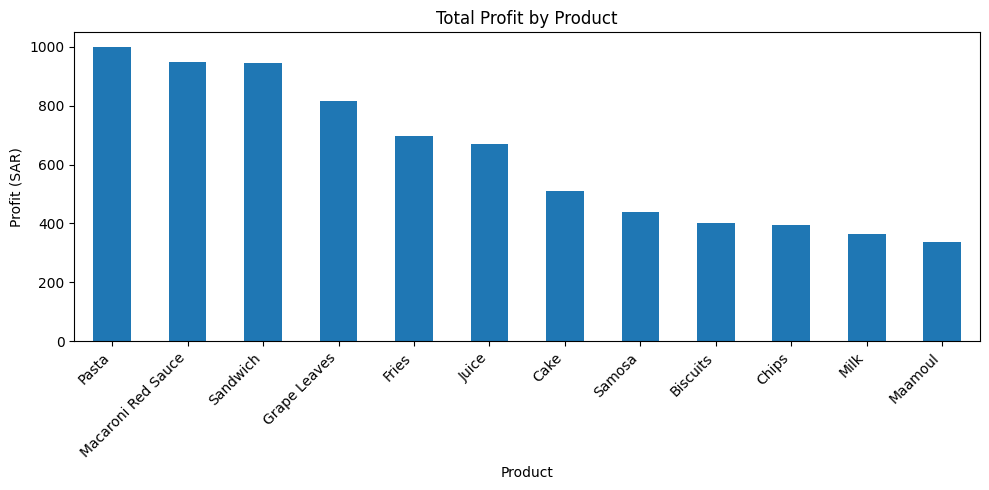

In [4]:
import matplotlib.pyplot as plt

profit_by_product.plot(kind="bar", figsize=(10, 5))
plt.title("Total Profit by Product")
plt.xlabel("Product")
plt.ylabel("Profit (SAR)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [5]:
waste = df.groupby("Product").agg(
    Prepared=("Prepared", "sum"),
    Leftover=("Leftover", "sum")
)
waste["Leftover_%"] = (waste["Leftover"] / waste["Prepared"] * 100).round(1)
waste = waste.sort_values("Leftover_%", ascending=False)
print(waste)

                    Prepared  Leftover  Leftover_%
Product                                           
Chips                    992       206        20.8
Fries                    586       121        20.6
Sandwich                 586       114        19.5
Grape Leaves             402        76        18.9
Samosa                   773       144        18.6
Macaroni Red Sauce       387        71        18.3
Biscuits                 803       133        16.6
Pasta                    399        66        16.5
Maamoul                  504        83        16.5
Cake                     498        74        14.9
Juice                    980       143        14.6
Milk                     596        78        13.1


In [6]:
df["Waste_Cost"] = df["Leftover"] * df["Cost"]
waste_cost = df.groupby("Product")["Waste_Cost"].sum().sort_values(ascending=False).round(1)
print(waste_cost)

Product
Sandwich              342.0
Macaroni Red Sauce    284.0
Grape Leaves          266.0
Pasta                 264.0
Chips                 206.0
Fries                 181.5
Juice                 171.6
Cake                  133.2
Biscuits              119.7
Samosa                115.2
Milk                  101.4
Maamoul                99.6
Name: Waste_Cost, dtype: float64


## Key finding (sample data)
Chips has the highest leftover percentage, but Sandwich causes the highest
waste cost in SAR. Reducing over-preparation of main meals saves more money.